# EN3160 — Image Processing and Machine Vision
## Assignment 02 - Fitting and Alignment

Name: K. D. Manatunga.

Index number: 230395T

GitHub repository: https://github.com/KaveeDiv23/Computer-Vision-Assignment-02

In [69]:
import cv2 as cv
import numpy as np
import matplotlib.pyplot as plt
from scipy.ndimage import gaussian_laplace, maximum_filter
from scipy.optimize import least_squares

plt.style.use("default")
plt.rcParams.update({
    "figure.facecolor": "white",
    "axes.facecolor": "white",
    "savefig.facecolor": "white",
    "text.color": "black",
    "axes.labelcolor": "black",
    "xtick.color": "black",
    "ytick.color": "black"
})
from IPython.display import HTML, display
display(HTML("""
<style>
.jp-CodeCell .jp-InputArea pre,
.jp-CodeCell .highlight pre,
.jp-CodeCell .cm-content,
div.input_area pre {
    font-size: 10px !important;
    line-height: 1.25 !important;
    white-space: pre-wrap !important;
    overflow-wrap: anywhere !important;
}
</style>
"""))

def load_rgb(filename, flag=cv.IMREAD_COLOR):
    im = cv.imread(f"a2images/{filename}", flag)
    if im is None: raise FileNotFoundError(filename)
    return cv.cvtColor(im, cv.COLOR_BGR2RGB)

#### Question 1

In [61]:
im = load_rgb("the_berry_farms_sunflower_field.jpeg", cv.IMREAD_REDUCED_COLOR_4)
gray=cv.cvtColor(im, cv.COLOR_RGB2GRAY).astype(np.float32)/255
h, w = gray.shape

sigmas = np.geomspace(1.5, 17, 24)
response=np.stack([s**2*gaussian_laplace(gray,float(s)) for s in sigmas])
peaks = np.argwhere((response == maximum_filter(response, size=(3,11,11))) &
                    (response > 0.18))

print(f"Image: {w} × {h}")
print(f"Sigma range: {sigmas[0]:.1f} - {sigmas[-1]:.1f}")
print("Interest points:", len(peaks))

Image: 360 × 360
Sigma range: 1.5 - 17.0
Interest points: 179


In [34]:
hsv = cv.cvtColor(im,cv.COLOR_RGB2HSV)
yellow = cv.inRange(hsv,(12,95,65),(42,255,255)) > 0
flowers = []

for k,y,x in peaks:
    s = sigmas[k]; r = np.sqrt(2)*s; m = int(np.ceil(1.85*r))
    if y < 0.54*h or r < 2.4 or min(x-m,y-m) < 0 or x+m >= w or y+m >= h: continue
    yy,xx = np.ogrid[-m:m+1,-m:m+1]
    dist2 = xx**2+yy**2
    core = dist2 <= (0.65*r)**2
    ring = (dist2 >= (1.1*r)**2) & (dist2 <= (1.85*r)**2)
    patch = yellow[y-m:y+m+1,x-m:x+m+1]
    center_gray = gray[y-m:y+m+1,x-m:x+m+1][core].mean()

    if patch[ring].mean() < 0.75 or patch[core].mean() > 0.25 or center_gray >= 0.20: continue
    angles = np.arctan2(yy,xx)+np.pi
    coverage = sum(patch[ring & (angles>=j*np.pi/6) &
                   (angles<(j+1)*np.pi/6)].mean() >= 0.55 for j in range(12))
    if coverage < 10: continue

    flowers.append((int(x),int(y),float(s),float(r),float(response[k,y,x])))

flowers.sort(key=lambda f:-f[3])
print("Detected sunflower centers:",len(flowers))
for i,(x,y,s,r,score) in enumerate(flowers[:5],1):
    print(f"{i}. Center=({x},{y}), σ={s:.2f}, radius={r:.2f}")

Detected sunflower centers: 38
1. Center=(282,338), σ=7.31, radius=10.33
2. Center=(106,255), σ=5.92, radius=8.37
3. Center=(179,327), σ=5.92, radius=8.37
4. Center=(178,261), σ=5.32, radius=7.53
5. Center=(274,258), σ=4.79, radius=6.77


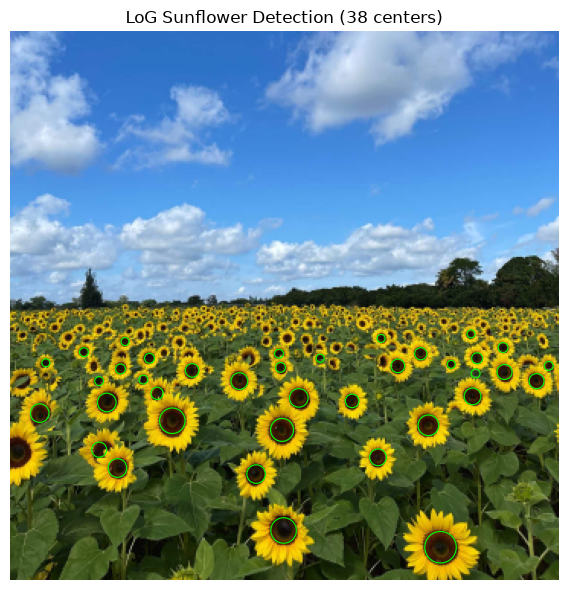

In [62]:
fig, ax = plt.subplots(figsize=(7,6))
ax.imshow(im)
for x,y,s,r,score in flowers:
    ax.add_patch(plt.Circle((x,y), r, fill=False, color="lime", lw=0.8))
ax.set_title(f"LoG Sunflower Detection ({len(flowers)} centers)")
ax.axis("off"); plt.tight_layout(); plt.show()

**Interpretation**

The LoG detector initially identified 179 interest points. However, not all of them represented sunflower centres, since dark areas between flowers and leaves can also produce strong responses. After applying the additional darkness and yellow-petal checks, 38 candidate centers were retained. The resulting circles are more concentrated on the dark central disks, with fewer obvious false detections.

The largest detected disk has a center of (282, 338) and an estimated radius of 10.33 pixels. Most of the larger detections are in the foreground, while the more distant flowers appear smaller due to perspective. The σ range of 1.5–17.0 pixels was chosen to cover different apparent flower sizes.

Although the result is improved, some smaller or overlapping sunflowers were not identified. This is due to their weaker contrast and the filtering conditions.

#### Question 02

##### 2 (a)

In [36]:
rng = np.random.default_rng(0)
n = 50; r_gt = 10; c_gt = np.array([2.,3.])
t = rng.uniform(0, 2*np.pi, n)
noise = (r_gt/16) * rng.standard_normal(n)
X_circ = np.column_stack((c_gt[0]+(r_gt+noise)*np.cos(t),
                          c_gt[1]+(r_gt+noise)*np.sin(t)))
x = np.linspace(-12,12,n)
X_line = np.column_stack((x, -x+2+rng.standard_normal(n)))
X = np.vstack((X_circ,X_line))

In [37]:
def line_model(p,q):
    v = q-p; L = np.linalg.norm(v)
    if L < 1e-9: return None
    u = np.array([-v[1],v[0]])/L
    return u, float(u@p)

def line_error(X,model):
    u,d = model
    return np.abs(X@u-d)

def fit_tls(X):
    c = X.mean(axis=0)
    u = np.linalg.svd(X-c)[2][-1]
    return u, float(u@c)

def ransac_line(X,seed=10,threshold=0.85,n_iter=1500):
    rg = np.random.default_rng(seed); best = None
    for _ in range(n_iter):
        idx = rg.choice(len(X),2,replace=False)
        model = line_model(*X[idx])
        if model is None: continue
        e = line_error(X,model); mask = e < threshold
        score = (mask.sum(),-np.median(e[mask]) if mask.any() else -np.inf)
        if best is None or score > best[0]:
            best = (score,idx,model,mask)
    _,idx,hyp,mask = best
    if mask.sum() < 30: raise RuntimeError("Insufficient line consensus")
    for _ in range(3):
        model = fit_tls(X[mask])
        new = line_error(X,model) < threshold
        if np.array_equal(mask,new): break
        mask = new
    return {"sample":idx,"initial":hyp,"model":fit_tls(X[mask]),"mask":mask}

In [38]:
line = ransac_line(X)
u,d = line["model"]
rem = X[~line["mask"]]

print("Line inliers:",line["mask"].sum())
print(f"Line: {u[0]:.4f}x + {u[1]:.4f}y = {d:.4f}")
print("Unit-normal length:",np.linalg.norm(u))
print("Remaining points:",len(rem))

Line inliers: 44
Line: 0.7049x + 0.7093y = 1.7045
Unit-normal length: 1.0
Remaining points: 56


**Interpretation**

A perpendicular-distance threshold of 0.85 was used to account for the noise while avoiding an excessively large consensus. With this threshold, RANSAC identified 44 inliers and the refined line was 0.7049x+0.7093y=1.7045.
The estimated line has almost the same slope as the original line y=-x+2, although its position is slightly shifted. This is expected because the points contain random noise and some circle points lie close to the line. The estimated normal also has a magnitude of 1, satisfying the required constraint.

##### 2 (b)

In [11]:
def circle_model(pts):
    p,q,r = pts
    A = 2*np.vstack((q-p,r-p))
    if abs(np.linalg.det(A)) < 1e-5: return None
    b = np.array([q@q-p@p,r@r-p@p])
    c = np.linalg.solve(A,b); R = np.linalg.norm(p-c)
    if not np.isfinite(R) or not 1 < R < 40: return None
    return (*c,R)

def circle_error(X,c):
    return np.abs(np.linalg.norm(X-np.array(c[:2]),axis=1)-c[2])

def ransac_circle(X,seed=11,threshold=0.85,n_iter=2500):
    rg = np.random.default_rng(seed); best = None
    for _ in range(n_iter):
        idx = rg.choice(len(X),3,replace=False)
        model = circle_model(X[idx])
        if model is None: continue
        e = circle_error(X,model); mask = e < threshold
        score = (mask.sum(),-np.median(e[mask]) if mask.any() else -np.inf)
        if best is None or score > best[0]:
            best = (score,idx,model,mask)
    _,idx,hyp,mask = best
    if mask.sum() < 30: raise RuntimeError("Insufficient circle consensus")
    for _ in range(3):
        fit = least_squares(
            lambda m: np.linalg.norm(X[mask]-m[:2],axis=1)-m[2],
            hyp,bounds=([-np.inf,-np.inf,0.01],[np.inf,np.inf,50])
        ).x
        new = circle_error(X,fit) < threshold
        if np.array_equal(mask,new): break
        mask = new
    fit = least_squares(
        lambda m: np.linalg.norm(X[mask]-m[:2],axis=1)-m[2],
        fit,bounds=([-np.inf,-np.inf,0.01],[np.inf,np.inf,50])
    ).x
    return {"sample":idx,"initial":hyp,"model":fit,"mask":mask}

In [39]:
circ = ransac_circle(rem)
cx,cy,r = circ["model"]
print("Circle inliers:",circ["mask"].sum())
print(f"Center: ({cx:.4f}, {cy:.4f})")
print(f"Radius: {r:.4f}")

Circle inliers: 40
Center: (2.1500, 2.7357)
Radius: 9.9402


**Interpretation**

After removing the 44 line inliers, 56 points remained for circle fitting. Using a radial error threshold of 0.85, RANSAC identified 40 circle inliers. The refined circle has a center of (2.1500, 2.7357) and a radius of 9.9402.
Compared with the actual center (2, 3) and radius 10, the fitted circle is reasonably accurate. The radius differs by only about 0.06 units. The small shift in the center is likely caused by the added noise and the removal of some circle points that were also close to the estimated line.

##### 2 (c)

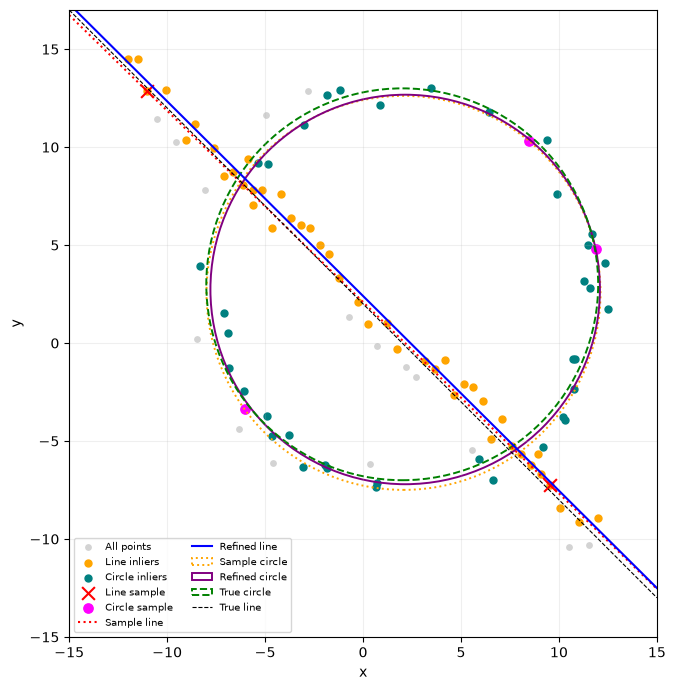

In [63]:
fig,ax = plt.subplots(figsize=(7,7))
ax.scatter(X[:,0],X[:,1],s=15,c="lightgray",label="All points")
ax.scatter(X[line["mask"],0],X[line["mask"],1],s=25,c="orange",label="Line inliers")
ax.scatter(rem[circ["mask"],0],rem[circ["mask"],1],s=25,c="teal",label="Circle inliers")
ax.scatter(*X[line["sample"]].T,s=85,c="red",marker="x",label="Line sample")
ax.scatter(*rem[circ["sample"]].T,s=45,c="magenta",label="Circle sample")

xx = np.linspace(-15,15,300)
for model,style,label in [(line["initial"],"r:","Sample line"),
                           (line["model"],"b-","Refined line")]:
    u,d = model
    if abs(u[1]) > 1e-8:
        ax.plot(xx,(d-u[0]*xx)/u[1],style,label=label)
    else:
        ax.axvline(d/u[0],color="blue",label=label)

for model,color,style,label in [(circ["initial"],"orange",":","Sample circle"),
                                 (circ["model"],"purple","-","Refined circle"),
                                 ((2,3,10),"green","--","True circle")]:
    ax.add_patch(plt.Circle(model[:2],model[2],fill=False,
                             color=color,ls=style,lw=1.4,label=label))

ax.plot(xx,-xx+2,"k--",lw=0.8,label="True line")
ax.set(xlim=(-15,15),ylim=(-15,17),xlabel="x",ylabel="y")
ax.set_aspect("equal"); ax.grid(alpha=0.2)
ax.legend(fontsize=7,ncol=2); plt.tight_layout(); plt.show()

**Interpretation**

The final plot shows that RANSAC successfully separates most of the line and circle points, even though the two models intersect. The refined line lies close to the ground-truth line, while the fitted circle almost overlaps the original circle.

There are a few points near the intersections that are difficult to assign correctly, since they lie close to both models. The sample-based estimates also differ slightly from the refined models, showing the benefit of fitting again using the full consensus rather than relying only on the randomly selected points.

##### 2 (d) — What happens if the circle is fitted first?

In [40]:
first = ransac_circle(X,seed=12)
fc = first["model"]

print("Circle-first")
print("Inliers:",first["mask"].sum())
print(f"Center: ({fc[0]:.4f}, {fc[1]:.4f}), Radius: {fc[2]:.4f}")
print("Line-first")
print(f"Inliers: {circ['mask'].sum()}, Center: ({cx:.4f}, {cy:.4f}), Radius: {r:.4f}")

Circle-first
Inliers: 47
Center: (2.1476, 2.7848), Radius: 9.9371
Line-first
Inliers: 40, Center: (2.1500, 2.7357), Radius: 9.9402


In [41]:
rem_idx = np.flatnonzero(~line["mask"])
seq_idx = rem_idx[circ["mask"]]

print("Line-first circle consensus:")
print("Circle points:", np.sum(seq_idx < 50),
      "| Line points:", np.sum(seq_idx >= 50))

print("Circle-first consensus:")
print("Circle points:", first["mask"][:50].sum(),
      "| Line points:", first["mask"][50:].sum())

Line-first circle consensus:
Circle points: 39 | Line points: 1
Circle-first consensus:
Circle points: 41 | Line points: 6


**Answer**

Fitting the circle first did not fail in this experiment. It produced a circle with center at (2.1476, 2.7848) and a radius of 9.9371, which are also close to the actual circle. However, its consensus contained 47 points, compared with 40 when the line was removed first.

Looking at the original point groups, the circle-first consensus included 6 points generated from the line, whereas the line-first approach left only 1 line point in the circle consensus. This is mainly because some line points lie close to the circle near their intersections.

Therefore, a larger consensus does not necessarily mean a better separation. Both approaches estimated the circle relatively well. But fitting the line first reduced the number of incorrectly included line points.

#### Question 03

##### 3 (a)

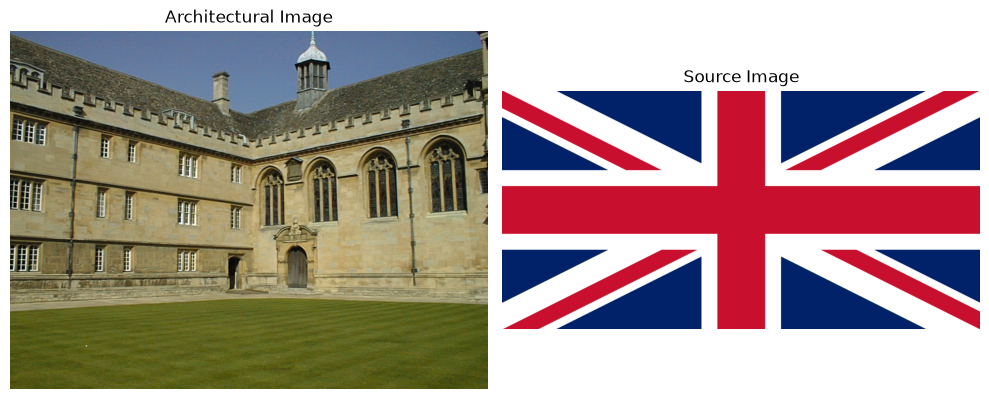

In [64]:
arch1 = load_rgb("wadham.jpg")
flag1 = load_rgb("flag.png")

fig,ax = plt.subplots(1,2,figsize=(10,4))
ax[0].imshow(arch1); ax[0].set_title("Architectural Image")
ax[1].imshow(flag1); ax[1].set_title("Source Image")
for a in ax: a.axis("off")
plt.tight_layout(); plt.show()

In [45]:
%matplotlib qt

In [46]:
def select_corners(im):
    fig,ax = plt.subplots(figsize=(10,7))
    ax.imshow(im)
    ax.set_title("Select 4 corners: TL → TR → BR → BL")
    plt.show(block=False)
    pts = plt.ginput(4,timeout=0)
    plt.close(fig)

    if len(pts) != 4:
        raise ValueError("Exactly four points are required")
    return np.float32(pts)

In [48]:
quad1 = select_corners(arch1)
print("Selected corners:\n",quad1)

Selected corners:
 [[144.8833  204.11002]
 [517.6269  288.4618 ]
 [517.6269  462.86475]
 [133.48442 445.76642]]


In [49]:
arch2 = load_rgb("billboard.webp")
flag2 = load_rgb("mountains.jpg")

quad2 = select_corners(arch2)
print("Second image corners:\n",quad2)

Second image corners:
 [[ 717.81055  275.12598]
 [1328.6573   264.48404]
 [1326.5289  1194.5886 ]
 [ 722.0673  1181.8184 ]]


In [50]:
quad1 = np.float32([
    [144.8833,204.11002],[517.6269,288.4618],
    [517.6269,462.86475],[133.48442,445.76642]
])

quad2 = np.float32([
    [717.81055,275.12598],[1328.6573,264.48404],
    [1326.5289,1194.5886],[722.0673,1181.8184]
])

In [51]:
%matplotlib inline

In [53]:
def overlay_image(bg,src,quad,alpha=0.85):
    h,w = bg.shape[:2]; sh,sw = src.shape[:2]
    dst = np.asarray(quad,dtype=np.float32)
    corners = np.float32([[0,0],[sw-1,0],[sw-1,sh-1],[0,sh-1]])
    if dst.shape != (4,2) or not cv.isContourConvex(dst.reshape(-1,1,2)):
        raise ValueError("Select four corners of a convex quadrilateral")

    H = cv.getPerspectiveTransform(corners,dst)
    warped = cv.warpPerspective(src,H,(w,h))
    mask = cv.warpPerspective(np.full((sh,sw),255,np.uint8),H,(w,h))/255.
    a = (alpha*mask)[...,None]
    result = np.clip(bg*(1-a)+warped*a,0,255).astype(np.uint8)
    return H,result

Homography 1:
 [[ 2.99039754e-01 -1.60165172e-02  1.44883301e+02]
 [ 1.02359513e-01  2.38194911e-01  2.04110016e+02]
 [ 2.02464947e-04 -3.09422047e-05  1.00000000e+00]]
Homography 2:
 [[ 5.98146447e-01  9.72833047e-03  7.17810547e+02]
 [-1.79662735e-02  7.56437117e-01  2.75125977e+02]
 [-2.62335655e-05  8.62081932e-06  1.00000000e+00]]


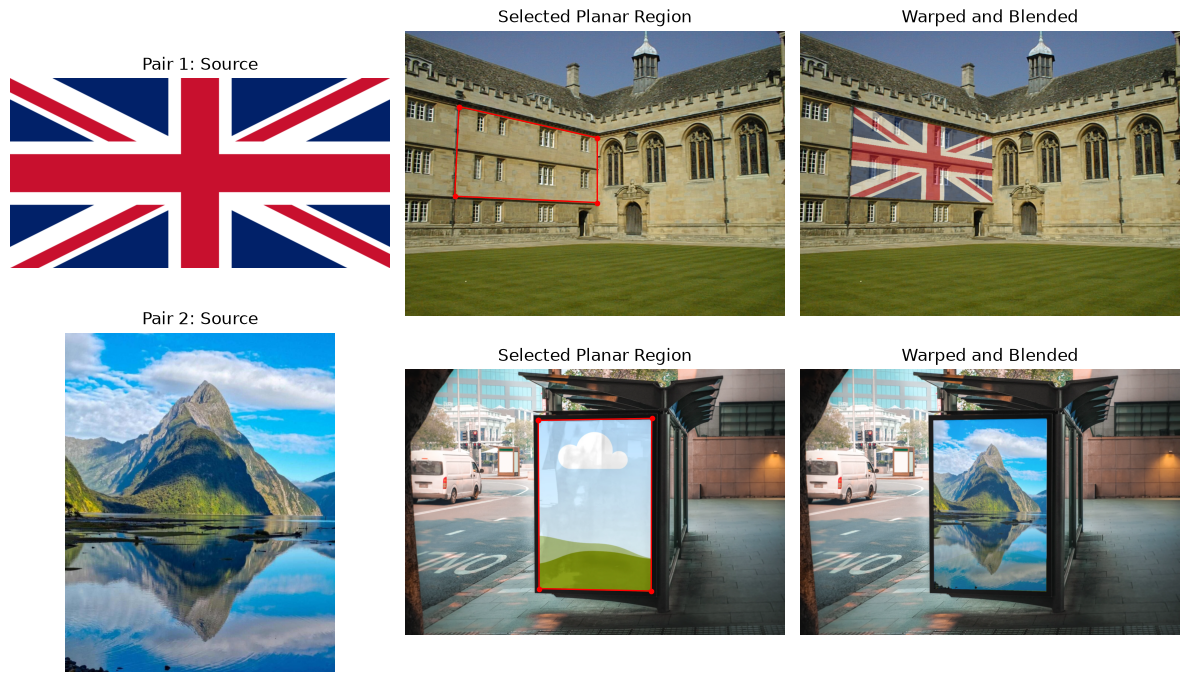

In [65]:
H1,result1 = overlay_image(arch1,flag1,quad1, alpha=0.5)
print("Homography 1:\n",H1)
H2,result2 = overlay_image(arch2,flag2,quad2)
print("Homography 2:\n",H2)

fig,ax = plt.subplots(2,3,figsize=(12,7))

for i,(bg,src,quad,result) in enumerate([
    (arch1,flag1,quad1,result1),
    (arch2,flag2,quad2,result2)
]):
    pts = np.vstack((quad,quad[0]))
    ax[i,0].imshow(src); ax[i,0].set_title(f"Pair {i+1}: Source")
    ax[i,1].imshow(bg)
    ax[i,1].plot(pts[:,0],pts[:,1],"ro-",lw=1,ms=3)
    ax[i,1].set_title("Selected Planar Region")
    ax[i,2].imshow(result); ax[i,2].set_title("Warped and Blended")

for a in ax.flat: a.axis("off")
plt.tight_layout(); plt.show()

**Interpretation**

For the first pair, the British flag was placed on the wall of Wadham College, as given in the example.

For the second pair, I chose a mountain landscape and a bus stop advertising display. I chose it because the rectangular display has clearly visible boundaries and represents a realistic application of image replacement. The portrait orientation of the mountain photograph also fits the advertising panel well.

#### Question 04

##### 4 (a)

Reference keypoints: 4500


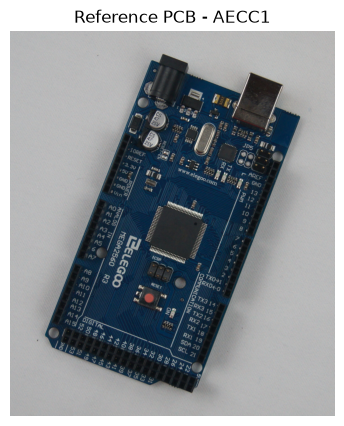

In [66]:
def load_small(filename,limit=1200):
    im = load_rgb(filename)
    h,w = im.shape[:2]; scale = min(1.,limit/max(h,w))
    if scale < 1: im = cv.resize(im,(round(w*scale),round(h*scale)))
    return im

ref = load_small("pcbs/AECC1.jpg")
ref_g = cv.cvtColor(ref,cv.COLOR_RGB2GRAY)
sift = cv.SIFT_create(nfeatures=4500)
kp_ref,des_ref = sift.detectAndCompute(ref_g,None)
print("Reference keypoints:",len(kp_ref))
plt.figure(figsize=(5,5))
plt.imshow(ref); plt.title("Reference PCB - AECC1")
plt.axis("off"); plt.show()

##### 4 (b), (c), (d)

In [30]:
pcb_names = ["AAAA1.jpg","ADAD1.jpg","AECC2.jpg","AECC3.jpg","AECC4.jpg"]
matcher = cv.BFMatcher(cv.NORM_L2)
pcb_results = {}

for name in pcb_names:
    moving = load_small("pcbs/"+name)
    gray = cv.cvtColor(moving,cv.COLOR_RGB2GRAY)
    kp,des = sift.detectAndCompute(gray,None)
    pairs = matcher.knnMatch(des,des_ref,k=2)
    good = [m for m,n in pairs if m.distance < 0.75*n.distance]

    if len(good) < 4:
        print(name,": insufficient matches"); continue

    src = np.float32([kp[m.queryIdx].pt for m in good]).reshape(-1,1,2)
    dst = np.float32([kp_ref[m.trainIdx].pt for m in good]).reshape(-1,1,2)
    H,inliers = cv.findHomography(src,dst,cv.RANSAC,4.0)
    if H is None:
        print(name,": homography failed"); continue

    h,w = ref.shape[:2]
    aligned = cv.warpPerspective(moving,H,(w,h))
    valid = cv.warpPerspective(np.full(gray.shape,255,np.uint8),
                               H,(w,h),flags=cv.INTER_NEAREST) > 0
    valid = cv.erode(valid.astype(np.uint8),np.ones((5,5),np.uint8)) > 0
    aligned_g = cv.cvtColor(aligned,cv.COLOR_RGB2GRAY)
    diff = cv.absdiff(ref_g,aligned_g)
    diff[~valid] = 0

    pcb_results[name] = {
        "matches":len(good),"inliers":int(inliers.sum()),
        "mean":float(diff[valid].mean()),"aligned":aligned,"diff":diff
    }

    if name == "AECC3.jpg":
        match_view = cv.drawMatches(moving,kp,ref,kp_ref,good,None,
                    matchesMask=inliers.ravel().tolist(),
                    flags=cv.DrawMatchesFlags_NOT_DRAW_SINGLE_POINTS)

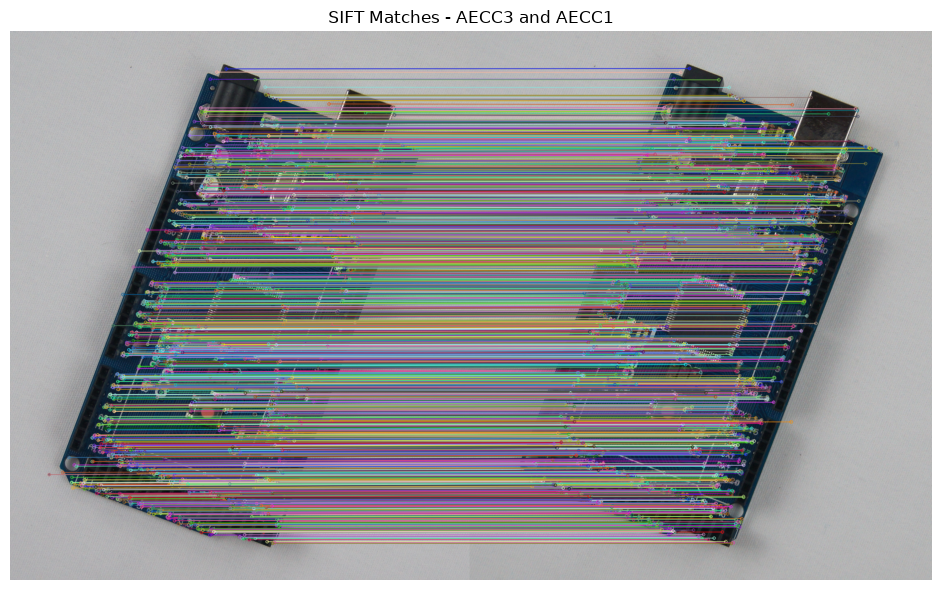

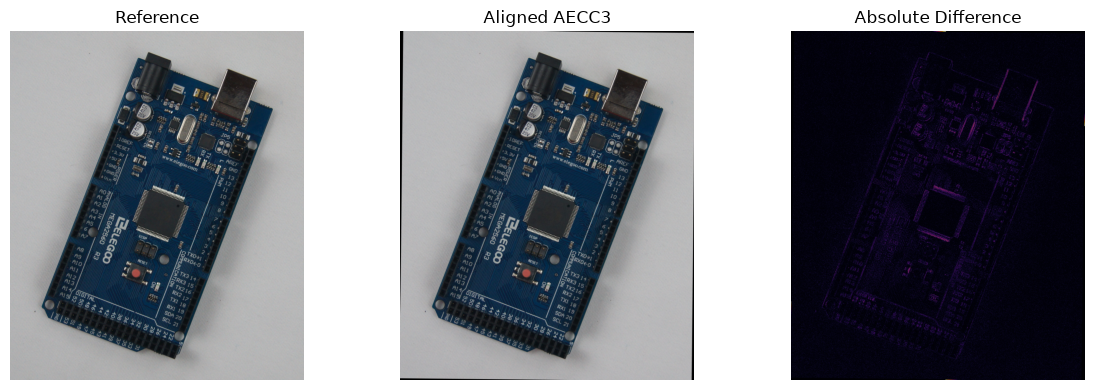

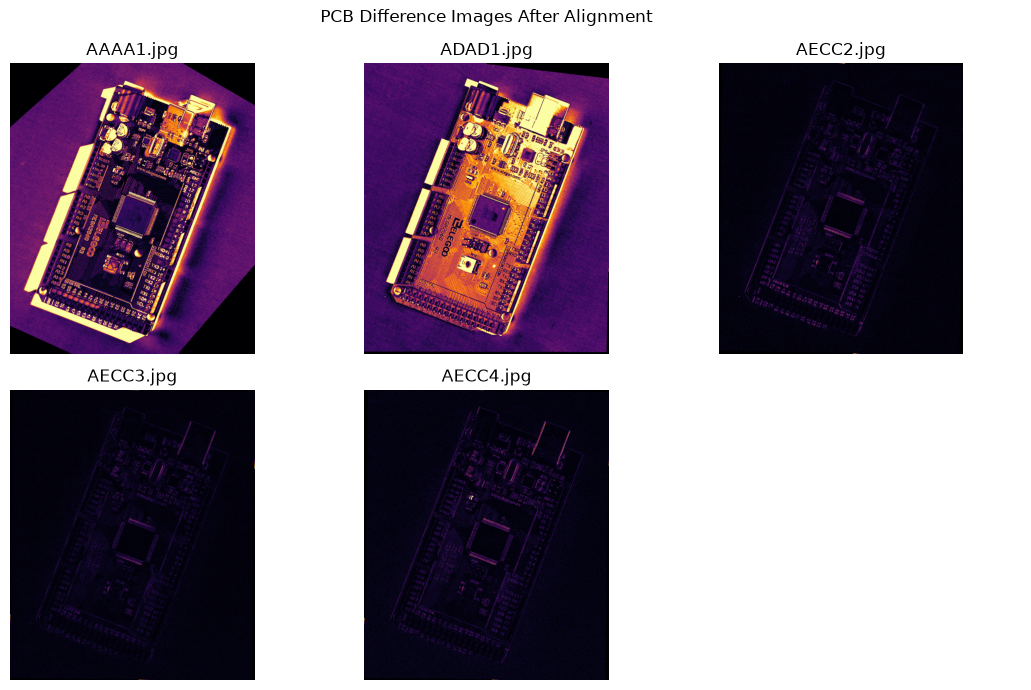

Image          Matches   Inliers   Mean Diff
AAAA1.jpg           46        23       28.14
ADAD1.jpg          253       166       31.05
AECC2.jpg         2156      1931        2.79
AECC3.jpg         2461      2223        2.52
AECC4.jpg         2136      1872        3.38


In [67]:
plt.figure(figsize=(12,6))
plt.imshow(match_view)
plt.title("SIFT Matches - AECC3 and AECC1")
plt.axis("off"); plt.tight_layout(); plt.show()

name = "AECC3.jpg"
data = pcb_results[name]

fig,ax = plt.subplots(1,3,figsize=(12,4))
ax[0].imshow(ref); ax[0].set_title("Reference")
ax[1].imshow(data["aligned"]); ax[1].set_title("Aligned AECC3")
ax[2].imshow(data["diff"],cmap="inferno",vmin=0,vmax=80)
ax[2].set_title("Absolute Difference")
for a in ax: a.axis("off")
plt.tight_layout(); plt.show()

fig,ax = plt.subplots(2,3,figsize=(11,7))
for a,name in zip(ax.flat,pcb_names):
    a.imshow(pcb_results[name]["diff"],cmap="inferno",vmin=0,vmax=80)
    a.set_title(name); a.axis("off")
ax.flat[-1].axis("off")
plt.suptitle("PCB Difference Images After Alignment")
plt.tight_layout(); plt.show()

print(f"{'Image':<12}{'Matches':>10}{'Inliers':>10}{'Mean Diff':>12}")
for name,data in pcb_results.items():
    print(f"{name:<12}{data['matches']:>10}{data['inliers']:>10}"
          f"{data['mean']:>12.2f}")

**Interpretation**

The PCB images showed noticeable differences in their matching and alignment results. AECC2, AECC3, and AECC4 produced a large number of reliable feature matches, with more than 1,800 RANSAC inliers each. Their mean differences were also very small ranging from 2.52 to 3.38 on the 0–255 grayscale intensity range.

This agrees with the displayed results, where these three aligned images closely resemble the AECC1 reference. Their difference images are mostly dark, with brighter regions around component edges and some board details.

In comparison, AAAA1 and ADAD1 produced much larger mean differences of 28.14 and 31.05. Their difference images contain bright regions across larger parts of the boards, suggesting more substantial appearance differences from the reference. AAAA1 also had only 23 RANSAC inliers, making its alignment less reliable than those of the AECC images.

Overall, the method worked well for images that closely resembled the reference. However, larger differences do not necessarily indicate defects, since changes in lighting, component arrangement and imperfect alignment can also contribute to the measured differences.

##### 4 (e)

**Answer — Question 4(e)**

The USB Type-B port, capacitors, and reset button are raised components rather than flat parts of the PCB. Although the homography aligns the board surface, these components may appear slightly different when photographed from different angles. This can cause their edges and positions to differ even after alignment.

Metallic surfaces, particularly around the USB port, can also reflect light differently, while taller components may cast shadows. As a result, the difference images show stronger responses around some of these regions.

Therefore, the high differences are not necessarily caused by missing or damaged components. They can also result from the three-dimensional shape of the components, lighting variations, and small remaining alignment errors.